# Round 1 portfolio allocation

We construct a USD 100 million ETF portfolio using constrained mean-variance optimization. This notebook shows the data, return and risk estimates, allocation, historical comparison and share quantities.

The estimates use Bloomberg ETF prices and FRED Treasury yields. Additional studies are in `supplementary_studies.ipynb`.

## 1. Portfolio rules

We target 8% annual volatility within the challenge's 7–9% band. The additional concentration caps and minimum exposures are our portfolio-policy choices.

The investment universe covers US equities (SPY and SCHD), emerging-market equities (VWO and EEMV), commodities (DBC), short-term Treasuries (VGSH) and short-term TIPS (STIP). The 5% minimum applies to each of these five groups, rather than to every ETF. XLE is excluded.

In [1]:
from pathlib import Path
from itertools import product
from decimal import Decimal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import norm
from IPython.display import display, Markdown

# Input paths are relative to the notebook folder.
ROOT = Path.cwd()
DATA = ROOT / "data"
RESULTS = ROOT / "results"
STUDIES = ROOT / "studies"
RESULTS.mkdir(exist_ok=True)
STUDIES.mkdir(exist_ok=True)

CAPITAL = 100_000_000
TARGET_VOLATILITY = 0.08
TRADING_COST = 0.001
ASSETS = ["SPY", "VWO", "EEMV", "DBC", "SCHD", "VGSH", "STIP"]
FIT_START = "2021-10"
FIT_END = "2026-09"
BACKTEST_START = "2016-11"
POLICY = {
    "risk_cap": 0.40,
    "capital_cap": 0.35,
    "equity_risk_cap": 0.65,
    "building_block_floor": 0.05,
    "bond_floor": 0.20,
}
GROUPS = {
    "US": ["SPY", "SCHD"],
    "EM": ["VWO", "EEMV"],
    "commodities": ["DBC"],
    "VGSH": ["VGSH"],
    "STIP": ["STIP"],
}
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})

ASSET_COLORS = {"SPY": "#315b83", "VWO": "#7587aa", "EEMV": "#7caac1",
                "DBC": "#c28d48", "SCHD": "#8b7a9d", "VGSH": "#8cac98", "STIP": "#b9cedb"}

def save_chart(figure, filename):
    figure.tight_layout()
    figure.savefig(RESULTS / (filename + ".png"), dpi=180, bbox_inches="tight")
    figure.savefig(RESULTS / (filename + ".pdf"), bbox_inches="tight")
    plt.show()

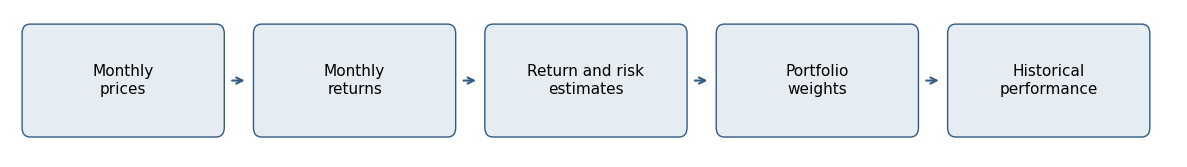

In [2]:
from matplotlib.patches import FancyBboxPatch

figure, axis = plt.subplots(figsize=(12, 1.8))
steps = ["Monthly\nprices", "Monthly\nreturns", "Return and risk\nestimates", "Portfolio\nweights", "Historical\nperformance"]
for i, label in enumerate(steps):
    box = FancyBboxPatch((i * 2.3, 0.4), 1.85, 0.8, boxstyle="round,pad=0.08",
                         facecolor="#e5edf3", edgecolor="#315b83")
    axis.add_patch(box)
    axis.text(i * 2.3 + 0.925, 0.8, label, ha="center", va="center", fontsize=11)
    if i < len(steps) - 1:
        axis.annotate("", xy=(i * 2.3 + 2.16, 0.8), xytext=(i * 2.3 + 1.98, 0.8),
                      arrowprops={"arrowstyle": "->", "color": "#315b83", "lw": 1.5})
axis.set(xlim=(-0.2, 11.4), ylim=(0.15, 1.4))
axis.axis("off")
save_chart(figure, "analysis_steps")

In [3]:
policy_description = pd.DataFrame([
    ["ETF capital cap", POLICY["capital_cap"], "Limit capital concentration"],
    ["ETF risk-share cap", POLICY["risk_cap"], "Limit estimated risk concentration"],
    ["Combined equity-risk cap", POLICY["equity_risk_cap"], "Limit dependence on equity risk"],
    ["Each building-block minimum", POLICY["building_block_floor"], "Retain meaningful exposure"],
    ["Combined VGSH + STIP minimum", POLICY["bond_floor"], "Retain a bond allocation"],
], columns=["Rule", "Limit", "Reason"])
display(policy_description.style.format({"Limit": "{:.0%}"}))

,Rule,Limit,Reason
0,ETF capital cap,35%,Limit capital concentration
1,ETF risk-share cap,40%,Limit estimated risk concentration
2,Combined equity-risk cap,65%,Limit dependence on equity risk
3,Each building-block minimum,5%,Retain meaningful exposure
4,Combined VGSH + STIP minimum,20%,Retain a bond allocation


## 2. Prices and return estimates

We use monthly USD closing prices from October 2011 to September 2026, saved in `data/month_end_prices.csv`. The original Bloomberg workbook is also in `data/`. The supplied series are used as total-return proxies.

Monthly returns are calculated as:
$$r_{i,t}=\frac{P_{i,t}}{P_{i,t-1}}-1$$
The estimation window contains 60 returns, October 2021–September 2026. Annual inputs are:
$$\hat\mu_i=12\,\overline r_i$$

$$\hat\Sigma=12\,\operatorname{Cov}(r)$$

$$\hat\sigma_i=\sqrt{12}\,s_i$$
We use sample covariance and standard deviation, with $n-1$ in the denominator. Historical average returns provide the optimization inputs.

In [4]:
prices = pd.read_csv(DATA / "month_end_prices.csv", index_col="month", parse_dates=True)[ASSETS]
returns = prices.pct_change(fill_method=None).iloc[1:]
training = returns.loc[FIT_START:FIT_END]
assert len(training) == 60 and np.isfinite(returns.to_numpy()).all()

annual_mean = training.mean() * 12
annual_covariance = training.cov() * 12
annual_inputs = pd.DataFrame({
    "annual_mean_input": annual_mean,
    "annual_volatility": training.std(ddof=1) * np.sqrt(12),
})

In [5]:
display(annual_inputs.style.format("{:.2%}"))

,annual_mean_input,annual_volatility
SPY,14.11%,15.67%
VWO,7.45%,14.74%
EEMV,6.65%,11.95%
DBC,13.71%,17.28%
SCHD,10.19%,15.10%
VGSH,1.83%,2.08%
STIP,2.88%,2.83%


### Prices over the estimation period

        Each series starts at 100 in September 2021. Indexing lets us compare price changes across funds with different share prices.

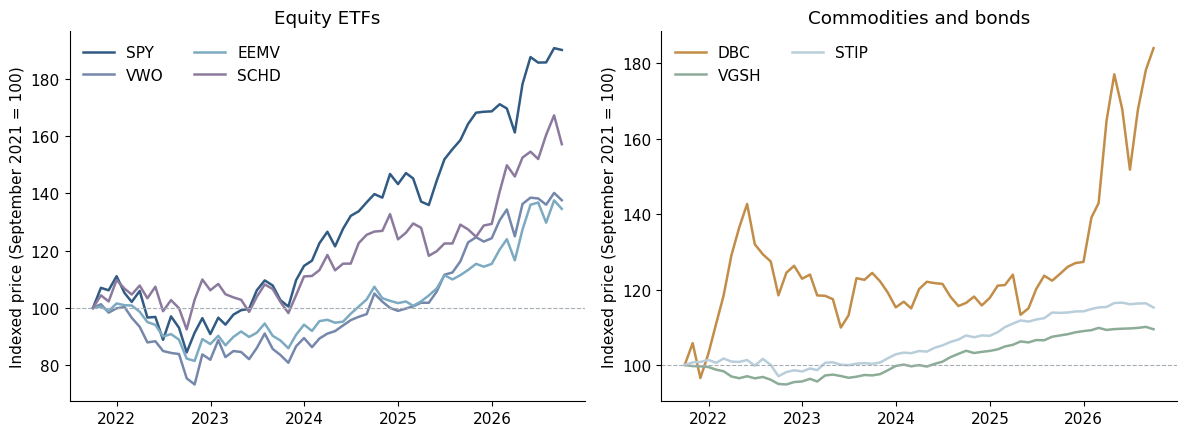

In [6]:
price_window = prices.loc["2021-09":FIT_END]
indexed_prices = price_window.div(price_window.iloc[0]) * 100
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
groups = [(["SPY", "VWO", "EEMV", "SCHD"], "Equity ETFs"),
          (["DBC", "VGSH", "STIP"], "Commodities and bonds")]
for axis, (tickers, title) in zip(axes, groups):
    for ticker in tickers:
        axis.plot(indexed_prices.index, indexed_prices[ticker], label=ticker,
                  color=ASSET_COLORS[ticker], lw=1.8)
    axis.axhline(100, color="#a5adb5", lw=0.8, linestyle="--")
    axis.set(title=title, ylabel="Indexed price (September 2021 = 100)")
    axis.legend(frameon=False, ncol=2)
save_chart(figure, "indexed_prices")

### Return and volatility inputs

        The plot places each ETF's annual historical mean against its annual volatility. These are the individual-fund inputs; portfolio risk also depends on covariance.

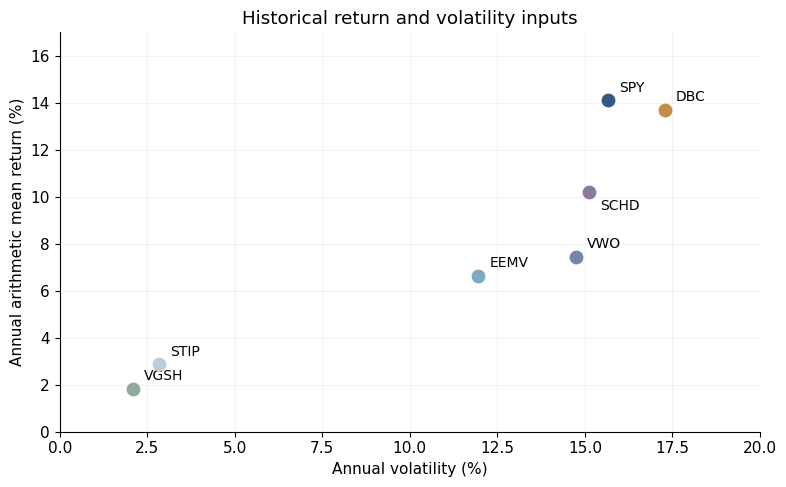

In [7]:
figure, axis = plt.subplots(figsize=(8, 5))
for ticker, row in annual_inputs.iterrows():
    x = row.annual_volatility * 100
    y = row.annual_mean_input * 100
    axis.scatter(x, y, s=80, color=ASSET_COLORS[ticker], zorder=3)
    offset = (8, -13) if ticker == "SCHD" else (8, 6)
    axis.annotate(ticker, (x, y), xytext=offset, textcoords="offset points", fontsize=10)
axis.set(title="Historical return and volatility inputs", xlabel="Annual volatility (%)",
         ylabel="Annual arithmetic mean return (%)", xlim=(0, 20), ylim=(0, 17))
axis.grid(alpha=0.15)
save_chart(figure, "return_volatility_inputs")

### Correlation and covariance

        Correlation shows the strength of co-movement on a scale from −1 to 1. The covariance matrix also reflects the size of each ETF's fluctuations. Its diagonal contains annual variances; off-diagonal entries enter the portfolio-risk calculation. Covariances below are expressed in squared percentage points.

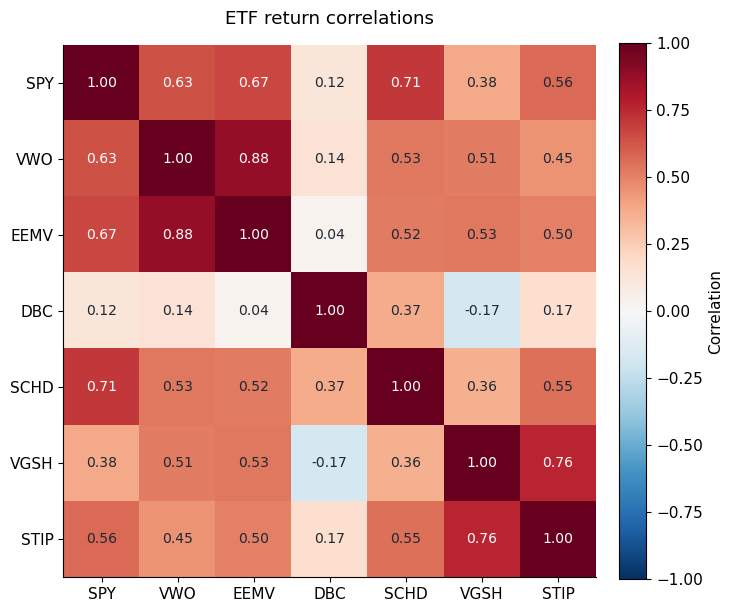

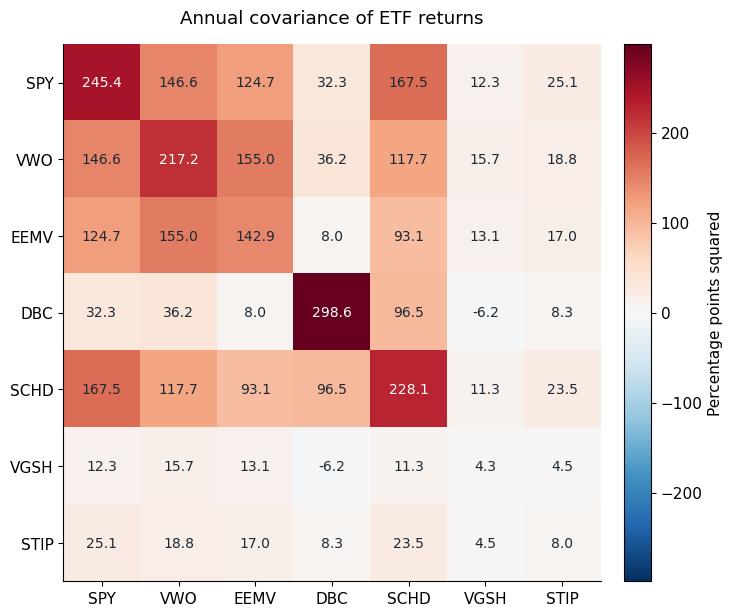

In [8]:
from matplotlib.colors import TwoSlopeNorm

def matrix_chart(matrix, title, colorbar_label, filename, decimals, limit):
    figure, axis = plt.subplots(figsize=(7.2, 6.3))
    color_scale = TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)
    image = axis.imshow(matrix.to_numpy(), cmap="RdBu_r", norm=color_scale)
    axis.set_xticks(range(len(matrix)), matrix.columns)
    axis.set_yticks(range(len(matrix)), matrix.index)
    axis.set_title(title, pad=15)
    for i in range(len(matrix)):
        for j in range(len(matrix)):
            value = matrix.iloc[i, j]
            color = "white" if abs(value) > limit * 0.6 else "#1c2833"
            axis.text(j, i, f"{value:.{decimals}f}", ha="center", va="center", color=color, fontsize=10)
    figure.colorbar(image, ax=axis, fraction=0.046, pad=0.04, label=colorbar_label)
    save_chart(figure, filename)

matrix_chart(training.corr(), "ETF return correlations", "Correlation",
             "correlation_matrix", decimals=2, limit=1)
covariance_percentage_points = annual_covariance * 10_000
matrix_chart(covariance_percentage_points, "Annual covariance of ETF returns",
             "Percentage points squared", "covariance_matrix", decimals=1,
             limit=float(np.abs(covariance_percentage_points.to_numpy()).max()))

## 3. Portfolio risk

Portfolio volatility depends on both the individual ETFs and their covariances:
$$\sigma_p=\sqrt{w^\top\Sigma w}$$
Each position's share of portfolio risk is:
$$RC_i=\frac{w_i(\Sigma w)_i}{w^\top\Sigma w}$$
Risk contributions sum to 100%. They differ from capital weights because ETFs have different volatilities and correlations.

In [9]:
def portfolio_volatility(weights, covariance):
    return float(np.sqrt(weights @ covariance @ weights))


def risk_shares(weights, covariance):
    variance = weights @ covariance @ weights
    return weights * (covariance @ weights) / variance


def risk_share_gradient(weights, covariance):
    # Analytic derivatives help SLSQP handle the nonlinear risk-share limits.
    marginal_covariance = covariance @ weights
    variance = weights @ marginal_covariance
    numerator_gradient = np.diag(marginal_covariance) + np.diag(weights) @ covariance
    variance_gradient = 2 * marginal_covariance
    return (numerator_gradient / variance
            - np.outer(weights * marginal_covariance, variance_gradient) / variance**2)


def policy_margins(weights, covariance, assets, policy):
    # Nonnegative margins mean the inequalities are satisfied.
    contributions = risk_shares(weights, covariance)
    equity_mask = np.array([ticker in {"SPY", "VWO", "EEMV", "SCHD"} for ticker in assets])
    margins = {
        "long_only": float(np.min(weights)),
        "capital_cap": float(policy["capital_cap"] - np.max(weights)),
        "risk_cap": float(policy["risk_cap"] - np.max(contributions)),
        "equity_risk_cap": float(policy["equity_risk_cap"] - contributions[equity_mask].sum()),
        "bond_floor": float(sum(weights[i] for i, ticker in enumerate(assets)
                                if ticker in {"VGSH", "STIP"}) - policy["bond_floor"]),
    }
    for group, tickers in GROUPS.items():
        exposure = sum(weights[i] for i, ticker in enumerate(assets) if ticker in tickers)
        floor = policy.get("floor_" + group, policy["building_block_floor"])
        margins[group + "_floor"] = float(exposure - floor)
    return pd.Series(margins)

## 4. Portfolio optimization

We choose all weights together to maximize the estimated annual return:
$$\max_w\;w^\top\hat\mu$$
Weights sum to one, are nonnegative and satisfy the policy limits. The volatility target is imposed as:
$$w^\top\hat\Sigma w=0.08^2$$
We use SciPy's SLSQP solver with 200 starting portfolios across two random seeds. The solver minimizes the negative return. Multiple starts reduce dependence on the initial portfolio; they do not establish a global optimum.

In [10]:
def optimize_weights(sample, policy, target=TARGET_VOLATILITY,
                     seeds=(12, 91), random_starts=100, warm_starts=()):
    assets = list(sample.columns)
    count = len(assets)
    covariance = sample.cov().to_numpy() * 12
    means = sample.mean().to_numpy() * 12
    equity_mask = np.array([ticker in {"SPY", "VWO", "EEMV", "SCHD"} for ticker in assets], dtype=float)

    constraints = [
        {"type": "eq", "fun": lambda w: w.sum() - 1,
         "jac": lambda w: np.ones(count)},
        {"type": "eq", "fun": lambda w: (w @ covariance @ w) / target**2 - 1,
         "jac": lambda w: 2 * covariance @ w / target**2},
        {"type": "ineq", "fun": lambda w: policy["risk_cap"] - risk_shares(w, covariance),
         "jac": lambda w: -risk_share_gradient(w, covariance)},
        {"type": "ineq", "fun": lambda w: policy["equity_risk_cap"] - equity_mask @ risk_shares(w, covariance),
         "jac": lambda w: -equity_mask @ risk_share_gradient(w, covariance)},
    ]
    for group, tickers in {**GROUPS, "bonds": ["VGSH", "STIP"]}.items():
        mask = np.array([ticker in tickers for ticker in assets], dtype=float)
        floor = (policy["bond_floor"] if group == "bonds"
                 else policy.get("floor_" + group, policy["building_block_floor"]))
        # Capture each group's mask and floor separately in these functions.
        constraints.append({"type": "ineq", "fun": lambda w, m=mask, f=floor: m @ w - f,
                            "jac": lambda w, m=mask: m})

    solutions = []
    diagnostics = []
    for seed in seeds:
        generator = np.random.default_rng(seed)
        starts = list(warm_starts) + list(generator.dirichlet(np.ones(count), random_starts))
        valid = []
        for initial_weights in starts:
            solution = minimize(
                fun=lambda w: -means @ w, x0=initial_weights, jac=lambda w: -means,
                bounds=[(0, policy["capital_cap"])] * count,
                constraints=constraints, method="SLSQP",
                options={"ftol": 1e-11, "maxiter": 500},
            )
            candidate = solution.x
            feasible = (abs(candidate.sum() - 1) < 1e-7
                        and abs(portfolio_volatility(candidate, covariance) - target) < 1e-7
                        and policy_margins(candidate, covariance, assets, policy).min() >= -1e-7)
            if solution.success and feasible:
                valid.append(solution)
        diagnostics.append({"seed": seed, "starts": len(starts), "verified_solutions": len(valid),
                            "best_mean_return": -min(s.fun for s in valid) if valid else np.nan})
        solutions.extend(valid)
    if not solutions:
        raise RuntimeError("No verified feasible allocation found; do not substitute arbitrary weights.")
    best = min(solutions, key=lambda solution: solution.fun)
    return best.x, pd.DataFrame(diagnostics)

### Rounded target weights

We report weights to 0.01 percentage point. If standard rounding exceeds a limit, we select the closest feasible combination of adjacent rounded values. The rounded portfolio remains fully invested and stays at or slightly below 8% estimated volatility.

In [11]:
exact_weights, solver_diagnostics = optimize_weights(training, POLICY)
covariance = annual_covariance.to_numpy()

def acceptable_rounding(weights):
    volatility = portfolio_volatility(weights, covariance)
    return (abs(weights.sum() - 1) < 1e-12
            and 0.07 <= volatility <= TARGET_VOLATILITY + 1e-10
            and policy_margins(weights, covariance, ASSETS, POLICY).min() >= -1e-10)

target_weights = np.round(exact_weights, 4)
target_weights[-1] = 1 - target_weights[:-1].sum()
if not acceptable_rounding(target_weights):
    # Try adjacent 0.01 percentage-point grid values, not a new portfolio search.
    lower_weights = np.floor(exact_weights * 10_000) / 10_000
    feasible_roundings = []
    for increments in product([0, 1], repeat=len(ASSETS)):
        candidate = lower_weights + np.array(increments) / 10_000
        if acceptable_rounding(candidate):
            feasible_roundings.append(candidate)
    if not feasible_roundings:
        raise RuntimeError("No nearby rounded allocation satisfies the policy limits.")
    target_weights = min(feasible_roundings, key=lambda w: np.sum((w - exact_weights)**2))

allocation = pd.DataFrame({
    "exact_weight": exact_weights,
    "target_weight": target_weights,
    "risk_share": risk_shares(target_weights, covariance),
    "target_value_usd": target_weights * CAPITAL,
}, index=ASSETS)
allocation.index.name = "ticker"
display(allocation.style.format({"exact_weight": "{:.6%}", "target_weight": "{:.2%}",
                                 "risk_share": "{:.2%}", "target_value_usd": "${:,.2f}"}))

,exact_weight,target_weight,risk_share,target_value_usd
ticker,,,,
SPY,26.083326%,26.08%,40.00%,"$26,080,000.00"
VWO,0.000000%,0.00%,0.00%,$0.00
EEMV,9.654292%,9.66%,8.62%,"$9,660,000.00"
DBC,26.956821%,26.95%,39.99%,"$26,950,000.00"
SCHD,3.276419%,3.28%,4.79%,"$3,280,000.00"
VGSH,5.000000%,5.00%,0.37%,"$5,000,000.00"
STIP,29.029141%,29.03%,6.23%,"$29,030,000.00"


In [12]:
policy_checks = policy_margins(target_weights, covariance, ASSETS, POLICY)
assert policy_checks.min() >= -1e-10
current_volatility = portfolio_volatility(target_weights, covariance)
current_normal_var = norm.ppf(0.95) * current_volatility / np.sqrt(12)
print(f"Estimated annual volatility: {current_volatility:.2%}")
print(f"Normal one-month 95% VaR: {current_normal_var:.2%} (${CAPITAL * current_normal_var:,.2f})")

Estimated annual volatility: 8.00%
Normal one-month 95% VaR: 3.80% ($3,798,447.76)


### Capital weights and risk contributions

        The comparison shows why a large bond allocation need not account for a large share of total risk. SPY and DBC are close to the individual 40% risk cap.

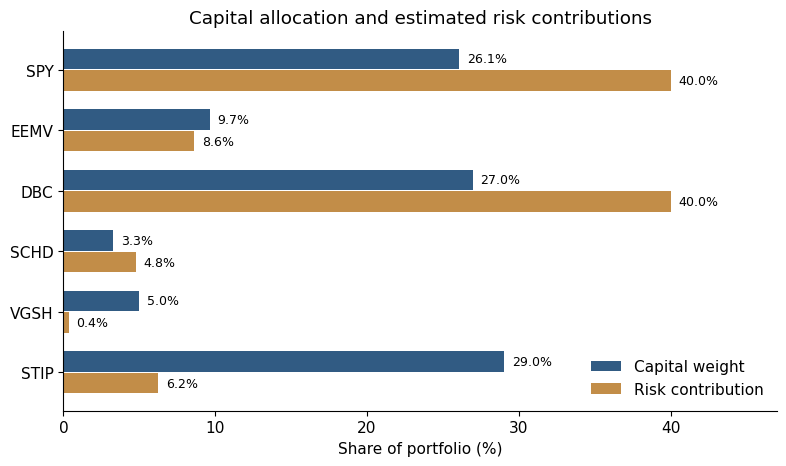

In [13]:
held = allocation.loc[allocation.target_weight > 1e-8]
figure, axis = plt.subplots(figsize=(8, 4.8))
positions_y = np.arange(len(held))
axis.barh(positions_y - 0.18, held.target_weight * 100, height=0.34,
          color="#315b83", label="Capital weight")
axis.barh(positions_y + 0.18, held.risk_share * 100, height=0.34,
          color="#c28d48", label="Risk contribution")
axis.set_yticks(positions_y, held.index)
axis.invert_yaxis()
axis.set(title="Capital allocation and estimated risk contributions", xlabel="Share of portfolio (%)", xlim=(0, 47))
for i, row in enumerate(held.itertuples()):
    axis.text(row.target_weight * 100 + 0.5, i - 0.18, f"{row.target_weight:.1%}", va="center", fontsize=9)
    axis.text(row.risk_share * 100 + 0.5, i + 0.18, f"{row.risk_share:.1%}", va="center", fontsize=9)
axis.legend(frameon=False, loc="lower right")
save_chart(figure, "capital_and_risk_weights")

## 5. Equal weight and risk parity

We compare the allocation with two rules using the same selected ETFs. Equal weight assigns $1/N$ of capital to each fund. Risk parity assigns $1/N$ of estimated risk to each fund.

The risk-parity weights are obtained by minimizing:
$$\frac12 x^\top\Sigma x-\sum_i b_i\log x_i$$

$$b_i=1/N$$
then normalizing $w=x/\sum x_i$.

These comparators do not use the additional MVO constraints. We do not apply leverage to bring their volatility to 8%.

In [14]:
held_assets = [ticker for ticker in ["SPY", "VWO", "EEMV", "DBC", "VGSH", "SCHD", "STIP"]
               if allocation.loc[ticker, "target_weight"] > 1e-8]
held_covariance = annual_covariance.loc[held_assets, held_assets].to_numpy()

def equal_risk_weights(covariance):
    # Equal risk budgeting: minimize 0.5 x'Σx - sum(b_i log(x_i)), then normalize x.
    count = len(covariance)
    scaled_covariance = covariance / np.mean(np.diag(covariance))
    budgets = np.ones(count) / count
    solution = minimize(
        lambda x: 0.5 * x @ scaled_covariance @ x - budgets @ np.log(x),
        np.ones(count), jac=lambda x: scaled_covariance @ x - budgets / x,
        bounds=[(1e-10, None)] * count, method="L-BFGS-B",
        options={"ftol": 1e-15, "gtol": 1e-10, "maxiter": 3000},
    )
    weights = solution.x / solution.x.sum()
    assert np.max(abs(risk_shares(weights, covariance) - budgets)) < 1e-7
    return weights

benchmark_weights = {
    "Constrained MVO": allocation.loc[held_assets, "target_weight"].to_numpy(),
    "Equal weight": np.ones(len(held_assets)) / len(held_assets),
    "Risk parity": equal_risk_weights(held_covariance),
}
benchmark_comparison = pd.DataFrame(index=held_assets)
for name, weights in benchmark_weights.items():
    benchmark_comparison[name + " weight"] = weights
    benchmark_comparison[name + " risk share"] = risk_shares(weights, held_covariance)
benchmark_volatility = pd.Series({name: portfolio_volatility(w, held_covariance)
                                  for name, w in benchmark_weights.items()}, name="estimated_volatility")
display(benchmark_comparison.style.format("{:.2%}"))
display(benchmark_volatility.to_frame().style.format("{:.2%}"))

,Constrained MVO weight,Constrained MVO risk share,Equal weight weight,Equal weight risk share,Risk parity weight,Risk parity risk share
SPY,26.08%,40.00%,16.67%,27.74%,5.18%,16.67%
EEMV,9.66%,8.62%,16.67%,18.21%,7.14%,16.67%
DBC,26.95%,39.99%,16.67%,19.98%,7.85%,16.67%
VGSH,5.00%,0.37%,16.67%,1.79%,47.65%,16.67%
SCHD,3.28%,4.79%,16.67%,28.32%,5.08%,16.67%
STIP,29.03%,6.23%,16.67%,3.95%,27.09%,16.67%


,estimated_volatility
Constrained MVO,8.00%
Equal weight,7.80%
Risk parity,3.75%


## 6. Risk-free rate

We use [FRED's one-month Treasury yield](https://fred.stlouisfed.org/series/DGS1MO). For each month, the last yield observed before the month begins is converted into a monthly return proxy:
$$r_{f,t}=\frac{y_{t^-}}{100}\frac{d_t}{365}$$
Here $d_t$ is the number of calendar days in the month. This approximates yield accrual; it is not a T-bill total-return index.

In [15]:
treasury = pd.read_csv(DATA / "fred_dgs1mo.csv", parse_dates=["observation_date"])
treasury["DGS1MO"] = pd.to_numeric(treasury["DGS1MO"], errors="coerce")
treasury = treasury.dropna(subset=["DGS1MO"]).set_index("observation_date").sort_index()
risk_free_rows = []
for month in returns.index:
    first_day = month.replace(day=1)
    prior = treasury.loc[treasury.index < first_day, "DGS1MO"]
    if prior.empty:
        raise ValueError(f"No Treasury yield available before {first_day.date()}.")
    annual_yield_percent = float(prior.iloc[-1])
    monthly_proxy = annual_yield_percent / 100 * month.days_in_month / 365
    risk_free_rows.append([month, prior.index[-1], annual_yield_percent, monthly_proxy])
risk_free_table = pd.DataFrame(risk_free_rows, columns=[
    "month", "yield_observation_date", "annual_yield_percent", "monthly_rf_proxy"
]).set_index("month")
risk_free = risk_free_table["monthly_rf_proxy"]

In [16]:
display(risk_free_table.head().style.format({"annual_yield_percent": "{:.2f}", "monthly_rf_proxy": "{:.4%}"}))

,yield_observation_date,annual_yield_percent,monthly_rf_proxy
month,,,
2011-11-30 00:00:00,2011-10-31 00:00:00,0.02,0.0016%
2011-12-31 00:00:00,2011-11-30 00:00:00,0.02,0.0017%
2012-01-31 00:00:00,2011-12-30 00:00:00,0.01,0.0008%
2012-02-29 00:00:00,2012-01-31 00:00:00,0.04,0.0032%
2012-03-31 00:00:00,2012-02-29 00:00:00,0.08,0.0068%


## 7. Historical performance

The backtest covers November 2016–September 2026, with 119 monthly returns. Each portfolio keeps its target allocation fixed, rebalancing monthly after price movements.

The allocation was estimated using data that overlap the backtest. Historical results also informed the choice of ETFs and rules. The comparison is therefore retrospective.

Gross portfolio return is $g_t=\sum_i w_i r_{i,t}$. After each month, weights drift to:
$$\tilde w_{i,t}=\frac{w_i(1+r_{i,t})}{1+g_t}$$
The next rebalance trades $T_{t+1}=\sum_i|w_i-\tilde w_{i,t}|$ of portfolio value. Purchases and sales are both counted. At inception $T_1=1$.

We assume a cost of 10 basis points per dollar traded:
$$r^{net}_t=(1-0.001T_t)(1+g_t)-1$$
Fund expenses are reflected in the price series.

### Performance measures

$$CAGR=\left[\prod_t(1+r_t^{net})\right]^{12/n}-1$$

$$\sigma_{realized}=\sqrt{12}\,s(r^{net})$$
$$Sharpe=\sqrt{12}\frac{\overline{r^{net}-r_f}}{s(r^{net})}$$
Drawdown measures the fall from the previous month-end peak, including initial capital. Historical one-month 95% VaR is minus the fifth percentile of net returns. The current normal-model VaR is $1.645\,\sigma_p/\sqrt{12}$, assuming zero mean and normal returns. Neither measure sets a maximum possible loss.

In [17]:
def simulate_fixed_weights(weights, asset_returns, trading_cost=TRADING_COST):
    drifted_weights = np.zeros(len(weights))
    rows = []
    for month, observations in asset_returns.iterrows():
        traded_fraction = float(np.abs(weights - drifted_weights).sum())
        gross_return = float(weights @ observations.to_numpy())
        net_return = (1 - trading_cost * traded_fraction) * (1 + gross_return) - 1
        rows.append([month, gross_return, traded_fraction, net_return])
        drifted_weights = weights * (1 + observations.to_numpy()) / (1 + gross_return)
    return pd.DataFrame(rows, columns=["month", "gross_return", "traded_fraction", "net_return"]).set_index("month")


def performance_statistics(net_returns):
    observations = net_returns.to_numpy()
    # Include initial wealth so an immediate first-month loss counts as drawdown.
    wealth = np.cumprod(np.r_[1.0, 1 + observations])
    drawdown = wealth / np.maximum.accumulate(wealth) - 1
    volatility = observations.std(ddof=1) * np.sqrt(12)
    excess_returns = net_returns - risk_free.reindex(net_returns.index)
    assert excess_returns.notna().all()
    return pd.Series({
        "months": len(observations),
        "cagr": wealth[-1]**(12 / len(observations)) - 1,
        "volatility": volatility,
        "sharpe": excess_returns.mean() * 12 / volatility,
        "max_month_end_drawdown": drawdown.min(),
        "historical_monthly_95pct_var": -np.quantile(observations, 0.05, method="linear"),
        "terminal_value_usd": CAPITAL * wealth[-1],
    })

In [18]:
evaluation = returns.loc[BACKTEST_START:, held_assets]
assert len(evaluation) == 119
simulations = {name: simulate_fixed_weights(weights, evaluation)
               for name, weights in benchmark_weights.items()}
backtest_returns = pd.DataFrame({name: frame["net_return"] for name, frame in simulations.items()})
backtest_summary = pd.DataFrame({name: performance_statistics(series)
                                 for name, series in backtest_returns.items()}).T
display(backtest_summary.style.format({"months": "{:.0f}", "cagr": "{:.2%}",
    "volatility": "{:.2%}", "sharpe": "{:.3f}", "max_month_end_drawdown": "{:.2%}",
    "historical_monthly_95pct_var": "{:.2%}", "terminal_value_usd": "${:,.2f}"}))

,months,cagr,volatility,sharpe,max_month_end_drawdown,historical_monthly_95pct_var,terminal_value_usd
Constrained MVO,119,9.04%,8.60%,0.768,-16.19%,3.68%,"$235,899,757.27"
Equal weight,119,8.49%,8.30%,0.731,-15.17%,3.55%,"$224,363,991.57"
Risk parity,119,4.46%,3.53%,0.561,-5.81%,1.21%,"$154,119,497.26"


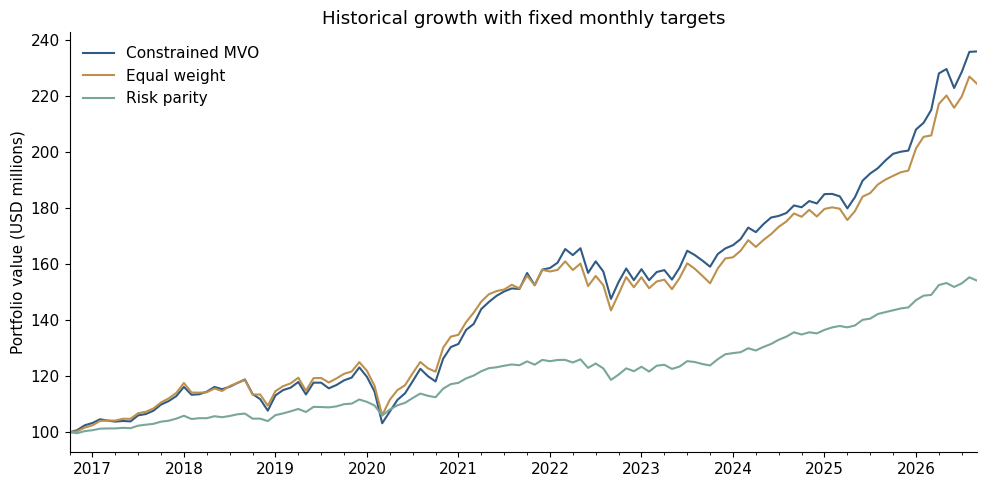

In [19]:
wealth = CAPITAL * (1 + backtest_returns).cumprod()
wealth.loc[evaluation.index[0] - pd.offsets.MonthEnd(1)] = CAPITAL
wealth = wealth.sort_index()
figure, axis = plt.subplots()
(wealth / 1_000_000).plot(ax=axis, color=["#315b83", "#bd904d", "#78a69b"])
axis.set(title="Historical growth with fixed monthly targets", ylabel="Portfolio value (USD millions)", xlabel="")
axis.legend(frameon=False)
save_chart(figure, "backtest_growth")

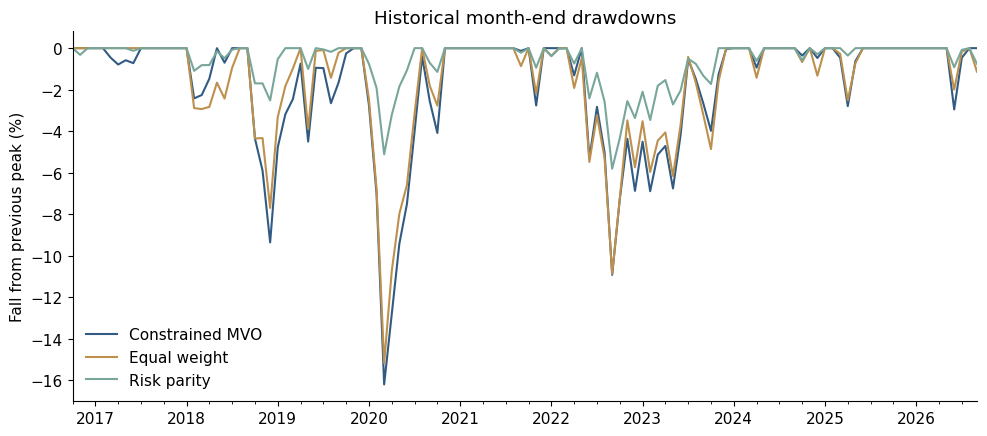

In [20]:
drawdowns = wealth.div(wealth.cummax()) - 1
figure, axis = plt.subplots(figsize=(10, 4.5))
(drawdowns * 100).plot(ax=axis, color=["#315b83", "#bd904d", "#78a69b"], lw=1.5)
axis.set(title="Historical month-end drawdowns", ylabel="Fall from previous peak (%)", xlabel="")
axis.legend(frameon=False, loc="lower left")
save_chart(figure, "backtest_drawdowns")

## 8. Share quantities

The share quantities use the closing prices of 16 October 2026 and USD 100 million initial capital:
$$\text{position value}=\text{shares}\times\text{closing price}$$

$$w_i^{actual}=\frac{\text{position value}_i}{100{,}000{,}000}$$
Whole-share rounding produces small differences from the target weights. VGSH is rounded upward to maintain the 5% minimum. The remaining USD 12.12 is held in cash. Position values exclude execution charges; residual cash is treated as having zero volatility.

In [21]:
positions = pd.read_csv(DATA / "positions.csv").set_index("ticker")
assert (positions["shares"] >= 0).all() and (positions["shares"] % 1 == 0).all()
value_cents = pd.Series({ticker: int(Decimal(str(row.closing_price_usd)) * 100) * int(row.shares)
                         for ticker, row in positions.iterrows()})
positions["position_value_usd"] = value_cents / 100
positions["actual_weight"] = positions["position_value_usd"] / CAPITAL
positions["target_weight"] = allocation["target_weight"].reindex(positions.index)
positions["difference_percentage_points"] = (positions["actual_weight"] - positions["target_weight"]) * 100
cash_cents = CAPITAL * 100 - int(value_cents.sum())
assert cash_cents >= 0
actual_weights = positions["actual_weight"].reindex(ASSETS, fill_value=0).to_numpy()
assert policy_margins(actual_weights, covariance, ASSETS, POLICY).min() >= -1e-10
actual_volatility = portfolio_volatility(actual_weights, covariance)
assert 0.07 <= actual_volatility <= 0.09
display(positions.style.format({"closing_price_usd": "${:,.2f}", "shares": "{:,.0f}",
    "position_value_usd": "${:,.2f}", "actual_weight": "{:.6%}", "target_weight": "{:.2%}",
    "difference_percentage_points": "{:+.6f}"}))
print(f"Invested: ${value_cents.sum() / 100:,.2f}; cash: ${cash_cents / 100:,.2f}")
print(f"Implemented estimated volatility: {actual_volatility:.6%}")

,closing_price_usd,shares,price_date,position_value_usd,actual_weight,target_weight,difference_percentage_points
ticker,,,,,,,
SPY,$763.25,"34,169",2026-10-16,"$26,079,489.25",26.079489%,26.08%,-0.000511
EEMV,$72.30,"133,610",2026-10-16,"$9,660,003.00",9.660003%,9.66%,+0.000003
DBC,$33.74,"798,756",2026-10-16,"$26,950,027.44",26.950027%,26.95%,+0.000027
VGSH,$57.69,"86,671",2026-10-16,"$5,000,049.99",5.000050%,5.00%,+0.000050
SCHD,$34.35,"95,488",2026-10-16,"$3,280,012.80",3.280013%,3.28%,+0.000013
STIP,$100.58,"288,630",2026-10-16,"$29,030,405.40",29.030405%,29.03%,+0.000405


Invested: $99,999,987.88; cash: $12.12
Implemented estimated volatility: 7.999573%


## 9. Results

The tables and figures are saved in `results/`. Each chart is available as PNG and PDF for use in the report.

The MVO allocation meets the selected policy limits. Its historical Sharpe is slightly higher than equal weight's. Risk parity has lower historical losses and a lower current volatility estimate, below the challenge's band. The supplementary notebook examines the effect of different limits, fitting windows and trading costs.

In [22]:
output_tables = {
    "allocation.csv": allocation,
    "annual_inputs.csv": annual_inputs,
    "annual_covariance.csv": annual_covariance,
    "correlations.csv": training.corr(),
    "monthly_etf_returns.csv": returns,
    "monthly_risk_free.csv": risk_free_table,
    "benchmark_comparison.csv": benchmark_comparison,
    "benchmark_volatility.csv": benchmark_volatility.to_frame(),
    "backtest_summary.csv": backtest_summary,
    "monthly_backtest_returns.csv": backtest_returns,
    "monthly_wealth.csv": wealth,
    "positions.csv": positions,
}
for filename, table in output_tables.items():
    table.to_csv(RESULTS / filename)
print("Saved the calculated tables in results/.")

Saved the calculated tables in results/.
